Resumo por cluster (perfis de transação):

         count    avg_valor   avg_hora  avg_tentativas  pct_local_novo  \
cluster                                                                  
1           50  3165.952256   2.840000        9.600000        1.000000   
3          196    87.069977  12.127551        1.897959        1.000000   
0          423    91.648579  12.146572        2.026005        0.432624   
2          231    84.140566  10.528139        2.043290        0.000000   

         pct_online  score_prioridade  
cluster                                
1               1.0          3.000000  
3               1.0          1.225206  
0               0.0          0.672614  
2               1.0          0.239419  

Cluster com maior score de prioridade investigativa: 1

Amostras do cluster prioritário:
        valor_rs  hora  tentativas_24h  local_novo  online  cluster
29   2225.127974     1              10           1       1        1
38   4749.085404     5              15        

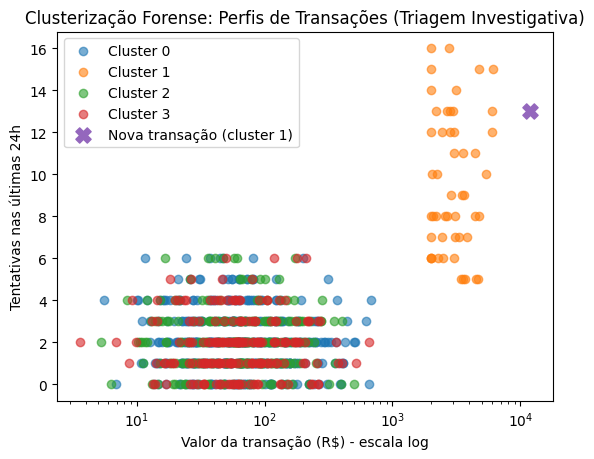

In [3]:
# EXEMPLO 2 — CLUSTERIZAÇÃO (NÃO SUPERVISIONADO) + INPUT MANUAL + GRÁFICO
# Contexto forense (mais simples e didático):
# Objetivo: agrupar TRANSACÕES por "perfil de comportamento" e permitir inserir uma nova
#           transação via input para ver em qual cluster ela cai.
# Problema real: triagem inicial de transações potencialmente fraudulentas (investigação),
#                quando ainda não há rótulos confiáveis (fraude/não fraude).
#
# Observação: clusterização NÃO "prova" fraude. Ela ajuda a identificar padrões e anomalias
# para priorizar investigação.

# Se estiver no Colab e não tiver scikit-learn:
# !pip -q install scikit-learn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

rng = np.random.default_rng(7)

# =============================
# 1) Gerando dataset sintético de transações (logs financeiros simplificados)
# =============================
n = 900

transacoes = pd.DataFrame({
    # Valor da transação em R$ (distribuição assimétrica típica de valores)
    "valor_rs": rng.lognormal(mean=4.2, sigma=0.9, size=n).clip(1, 20000),

    # Hora do dia (0-23)
    "hora": rng.integers(0, 24, size=n),

    # Tentativas de transação nas últimas 24h (contagem)
    "tentativas_24h": rng.poisson(2, size=n).clip(0, 30),

    # Transação em local/cidade diferente do padrão do usuário? (0/1)
    "local_novo": rng.integers(0, 2, size=n),

    # Operação online? (0/1)  -> e-commerce, app, internet banking
    "online": rng.integers(0, 2, size=n),
})

# Injetando um "grupo suspeito" didático:
# valores altos + madrugada + muitas tentativas + local novo + online
idx = rng.choice(n, size=50, replace=False)
transacoes.loc[idx, "valor_rs"] = rng.lognormal(mean=8.0, sigma=0.45, size=50).clip(2000, 20000)
transacoes.loc[idx, "hora"] = rng.choice([0, 1, 2, 3, 4, 5], size=50)
transacoes.loc[idx, "tentativas_24h"] = rng.poisson(10, size=50).clip(5, 30)
transacoes.loc[idx, "local_novo"] = 1
transacoes.loc[idx, "online"] = 1

FEATURES = ["valor_rs", "hora", "tentativas_24h", "local_novo", "online"]
X = transacoes[FEATURES].copy()

# =============================
# 2) Pipeline: escala + KMeans
# =============================
k = 4
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("kmeans", KMeans(n_clusters=k, random_state=42, n_init="auto"))
])

clusters = pipe.fit_predict(X)
transacoes["cluster"] = clusters

# =============================
# 3) Resumo por cluster + heurística de priorização investigativa
# =============================
summary = transacoes.groupby("cluster").agg(
    count=("cluster", "size"),
    avg_valor=("valor_rs", "mean"),
    avg_hora=("hora", "mean"),
    avg_tentativas=("tentativas_24h", "mean"),
    pct_local_novo=("local_novo", "mean"),
    pct_online=("online", "mean"),
)

# Uma heurística didática para indicar cluster "mais prioritário":
# maior valor médio + maior % local_novo + maior tentativas
summary["score_prioridade"] = (
    (summary["avg_valor"] / summary["avg_valor"].max()) +
    summary["pct_local_novo"] +
    (summary["avg_tentativas"] / summary["avg_tentativas"].max())
)

summary = summary.sort_values("score_prioridade", ascending=False)

print("Resumo por cluster (perfis de transação):\n")
print(summary[["count", "avg_valor", "avg_hora", "avg_tentativas", "pct_local_novo", "pct_online", "score_prioridade"]])

prioritario = int(summary.index[0])
print(f"\nCluster com maior score de prioridade investigativa: {prioritario}")

print("\nAmostras do cluster prioritário:")
print(transacoes[transacoes["cluster"] == prioritario].head(10))

# =============================
# 4) INPUT MANUAL: inserir uma transação e obter cluster
# =============================
print("\n=== INSIRA OS DADOS DA NOVA TRANSAÇÃO (CASO EM INVESTIGAÇÃO) ===")

valor_rs = float(input("Valor da transação (R$): ").replace(",", "."))
hora = int(input("Hora do dia (0-23): "))
tentativas_24h = int(input("Tentativas nas últimas 24h (0-30): "))
local_novo = int(input("Local novo? (0=Não / 1=Sim): "))
online = int(input("Foi online? (0=Não / 1=Sim): "))

nova_transacao = pd.DataFrame([{
    "valor_rs": valor_rs,
    "hora": hora,
    "tentativas_24h": tentativas_24h,
    "local_novo": local_novo,
    "online": online
}])[FEATURES]

cluster_novo = int(pipe.predict(nova_transacao)[0])

print("\n=== RESULTADO DA TRIAGEM ===")
print(nova_transacao.to_string(index=False))
print(f"\nCluster atribuído: {cluster_novo}")

if cluster_novo == prioritario:
    print("Interpretação: a transação caiu no cluster de MAIOR prioridade investigativa (heurística de triagem).")
else:
    print("Interpretação: a transação caiu em outro perfil de comportamento. Avaliar em conjunto com outras evidências.")

# =============================
# 5) GRÁFICO DE PONTOS: Valor vs Tentativas
#    - Cada cluster com uma cor (default do matplotlib)
#    - Nova transação destacada
# =============================
plt.figure()
for c in sorted(transacoes["cluster"].unique()):
    subset = transacoes[transacoes["cluster"] == c]
    plt.scatter(subset["valor_rs"], subset["tentativas_24h"], label=f"Cluster {c}", alpha=0.6)

plt.scatter(
    [valor_rs], [tentativas_24h],
    marker="X", s=120,
    label=f"Nova transação (cluster {cluster_novo})"
)

plt.xscale("log")  # valores variam muito; log ajuda na visualização
plt.xlabel("Valor da transação (R$) - escala log")
plt.ylabel("Tentativas nas últimas 24h")
plt.title("Clusterização Forense: Perfis de Transações (Triagem Investigativa)")
plt.legend()
plt.show()


# **Interpretação típica dos 4 clusters**

🔹 Cluster 1 – Perfil de Baixo Risco (Transações Rotineiras)

Características comuns:
- Valores baixos ou médios
- Poucas tentativas
- Local conhecido
- Horários comerciais
- Pode ser presencial

**Significado investigativo:** Esse grupo tende a representar comportamento normal do usuário. Não significa ausência de risco, mas baixa prioridade investigativa.

🔹 Cluster 2 – Perfil Digital Comum

Características comuns:
- Transações online frequentes
- Valores médios
- Algumas tentativas adicionais
- Pode ocorrer fora do horário comercial

**Significado investigativo:** Perfil típico de uso digital (apps, e-commerce). Pode exigir monitoramento leve, mas não é necessariamente anômalo.

🔹 Cluster 3 – Perfil de Alto Valor

Características comuns:
- Valores elevados
- Poucas tentativas
- Local conhecido

**Significado investigativo:**
Transações grandes podem indicar:
- Compras legítimas de alto valor
- Transferências financeiras
- Ou início de fraude sofisticada

Prioridade média a alta dependendo do contexto.

🔹 Cluster 4 – Perfil Anômalo / Prioritário

Características comuns:
- Valores altos
- Muitas tentativas em curto período
- Local novo
- Operações online
- Frequente em horário atípico (madrugada)

**Significado investigativo:**
Esse cluster tende a concentrar padrões compatíveis com:
- Ataques de força bruta
- Testes de cartão
- Uso indevido após vazamento
- Fraude transacional

Por isso o código marca esse como “cluster prioritário”.